# Breast Cancer Prediction using Machine Learning

**Goal:** Predict whether a breast tumor is **malignant** (cancerous) or **benign** (not cancerous) from 30 measurements of cell nuclei.

**Steps:**
1. Load and explore the data
2. Visualize important features
3. Preprocess (train/test split + scaling)
4. Train and compare 4 models
5. Evaluate the best model (confusion matrix, precision, recall)
6. Find the most important features

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## 2. Load and explore the data
The dataset (Wisconsin Breast Cancer dataset) is built into scikit-learn, so no download is needed.

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target   # 0 = malignant, 1 = benign

print("Shape:", df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Missing values:", df.isnull().sum().sum())
print()
print(df["target"].value_counts().rename({0: "Malignant (0)", 1: "Benign (1)"}))

Missing values: 0

target
Benign (1)       357
Malignant (0)    212
Name: count, dtype: int64


**Observation:** 569 samples, 30 features, no missing values. The classes are slightly imbalanced (more benign than malignant), so we also look at **precision and recall**, not only accuracy.

## 3. Visualize the data

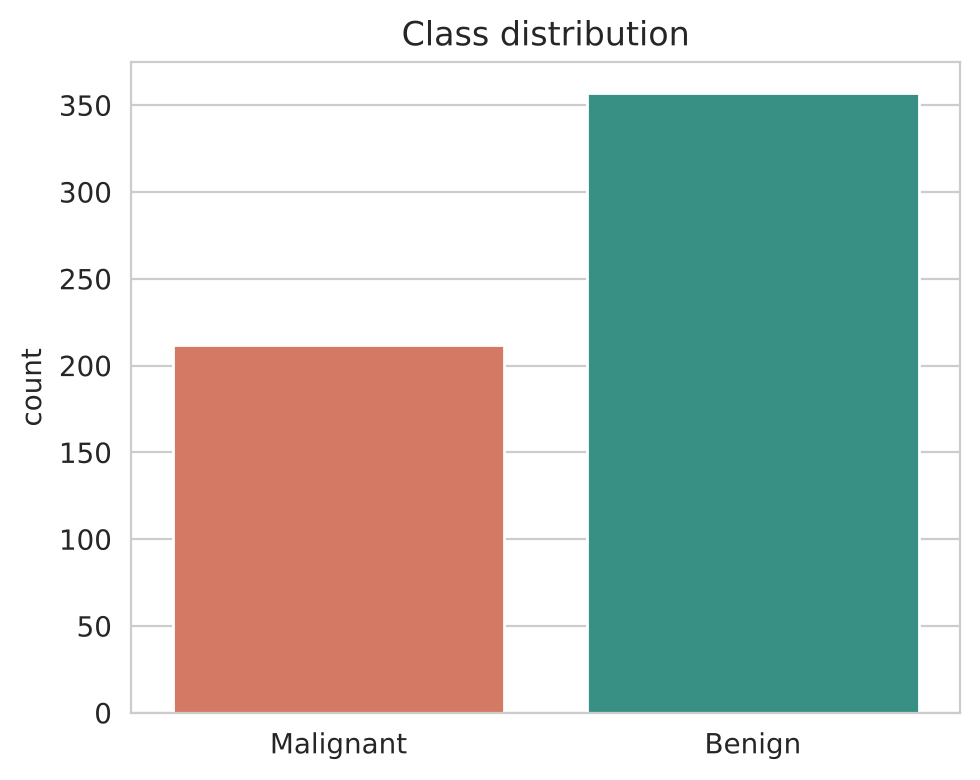

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df["target"].map({0: "Malignant", 1: "Benign"}), palette=["#e76f51", "#2a9d8f"], ax=ax)
ax.set_title("Class distribution")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("images/class_distribution.png", dpi=120)
plt.show()

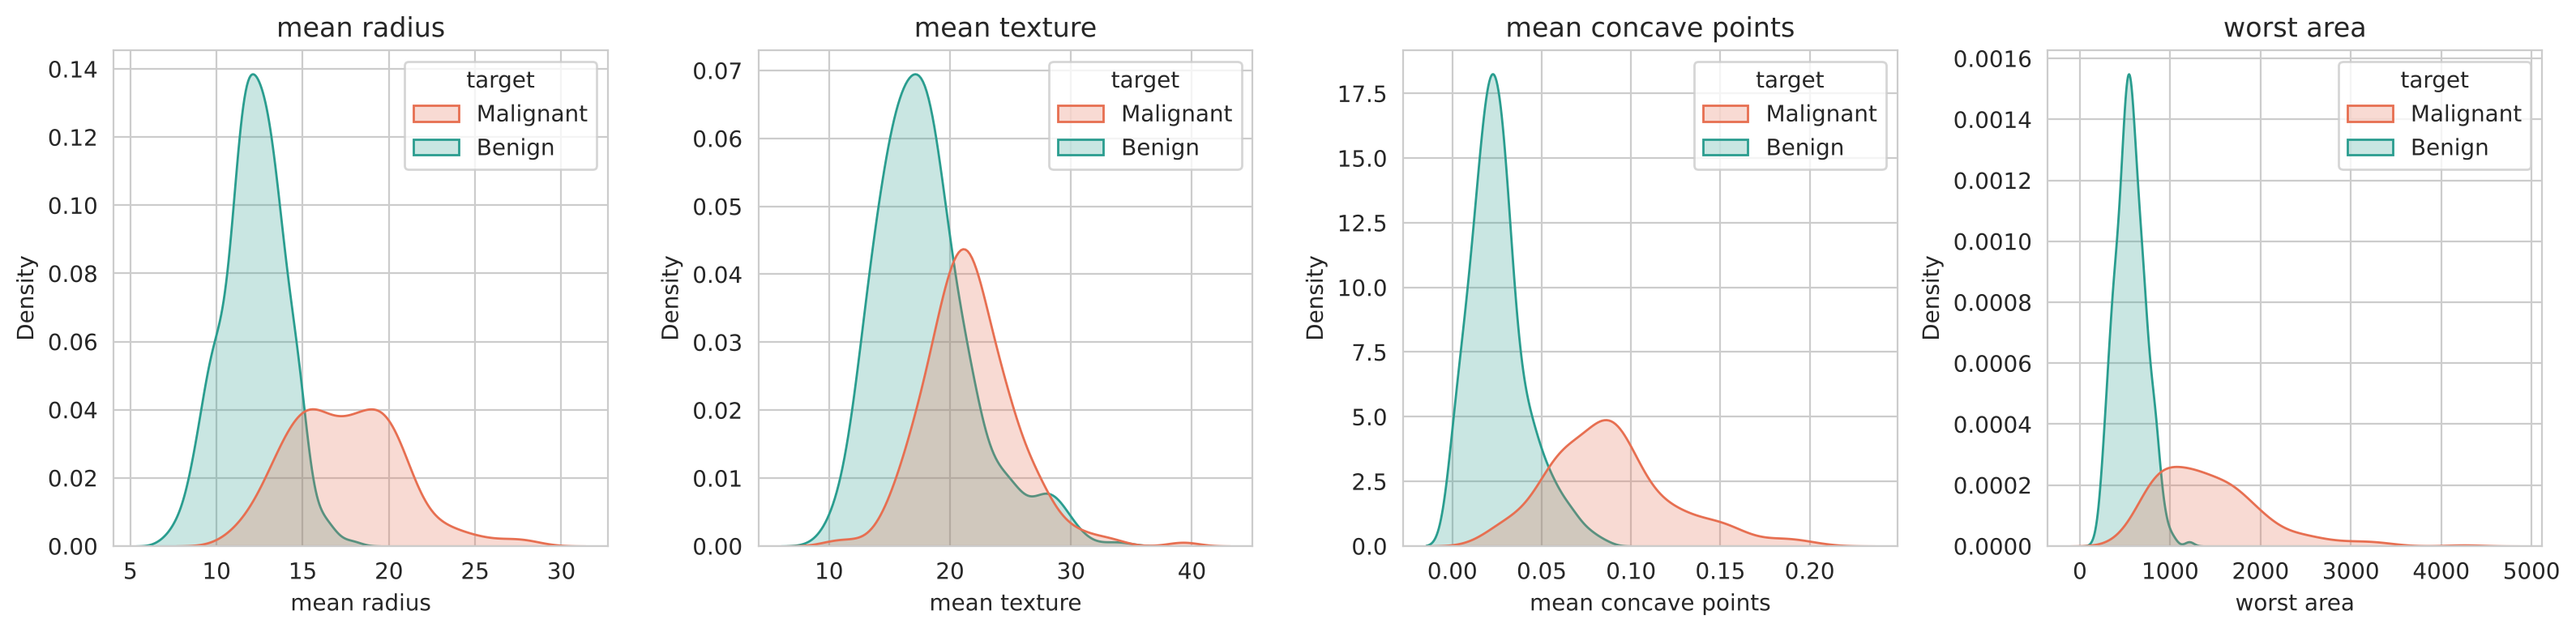

In [5]:
# Compare a few key features between malignant and benign tumors
features = ["mean radius", "mean texture", "mean concave points", "worst area"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, features):
    sns.kdeplot(data=df, x=f, hue=df["target"].map({0: "Malignant", 1: "Benign"}),
                fill=True, palette=["#e76f51", "#2a9d8f"], ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.savefig("images/feature_distributions.png", dpi=120)
plt.show()

**Observation:** Malignant tumors clearly have larger radius, area and more concave points. These features should be strong predictors.

## 4. Preprocessing
- Split into 80% training and 20% testing (stratified so both sets keep the same class ratio)
- Scale features with `StandardScaler`, because models like Logistic Regression and KNN are sensitive to feature scale

In [6]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit only on training data (avoids data leakage)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 5. Train and compare models
We use 5-fold cross-validation on the training set plus accuracy on the test set.

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    cv = cross_val_score(model, X_train_scaled, y_train, cv=5).mean()
    model.fit(X_train_scaled, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test_scaled))
    results.append({"Model": name, "CV Accuracy": round(cv, 4), "Test Accuracy": round(test_acc, 4)})

results_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
results_df

,Model,CV Accuracy,Test Accuracy
0,Logistic Regression,0.9802,0.9825
1,K-Nearest Neighbors,0.9670,0.9561
2,Random Forest,0.9604,0.9561
3,Decision Tree,0.9099,0.9123


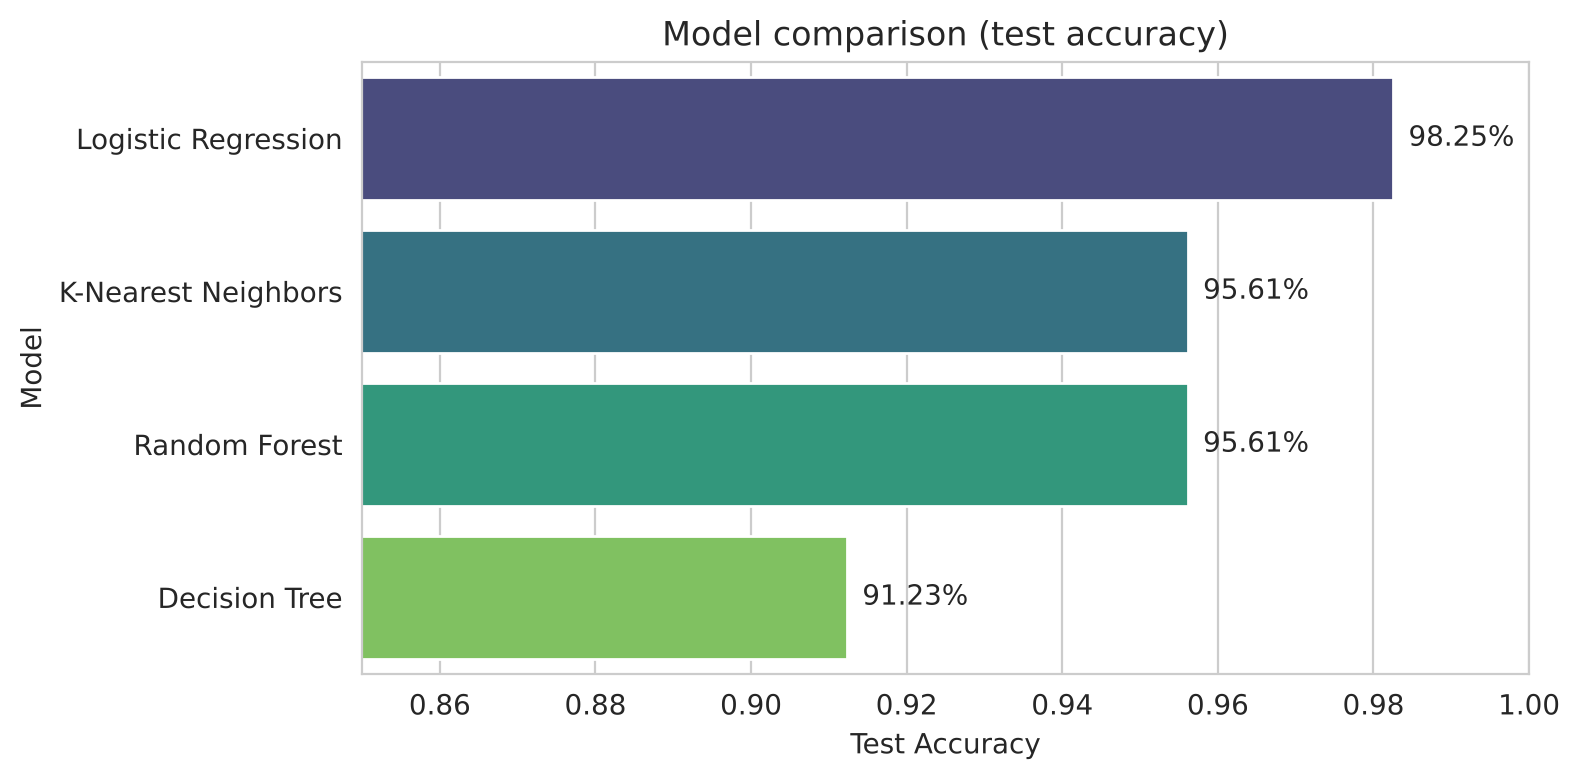

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=results_df, y="Model", x="Test Accuracy", palette="viridis", ax=ax)
ax.set_xlim(0.85, 1.0)
for i, v in enumerate(results_df["Test Accuracy"]):
    ax.text(v + 0.002, i, f"{v:.2%}", va="center")
ax.set_title("Model comparison (test accuracy)")
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=120)
plt.show()

## 6. Evaluate the best model
In medical problems, **recall for the malignant class** matters most: missing a cancer case (false negative) is much worse than a false alarm.

In [9]:
best_name = results_df.loc[0, "Model"]
best_model = models[best_name]
y_pred = best_model.predict(X_test_scaled)

print("Best model:", best_name)
print()
print(classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

Best model: Logistic Regression

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



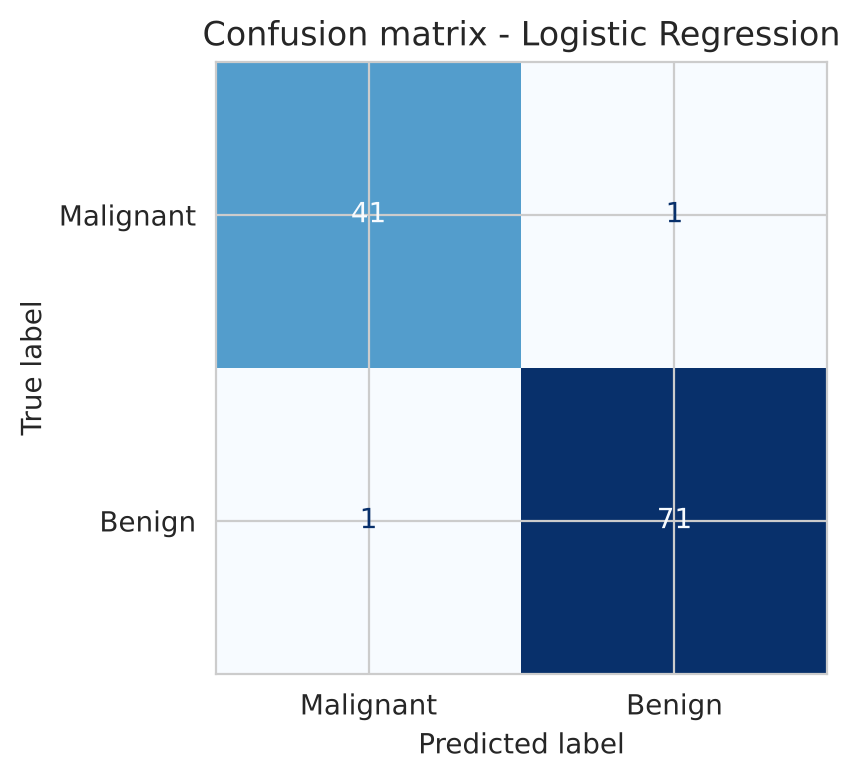

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Malignant", "Benign"]).plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=120)
plt.show()

## 7. Feature importance (Random Forest)

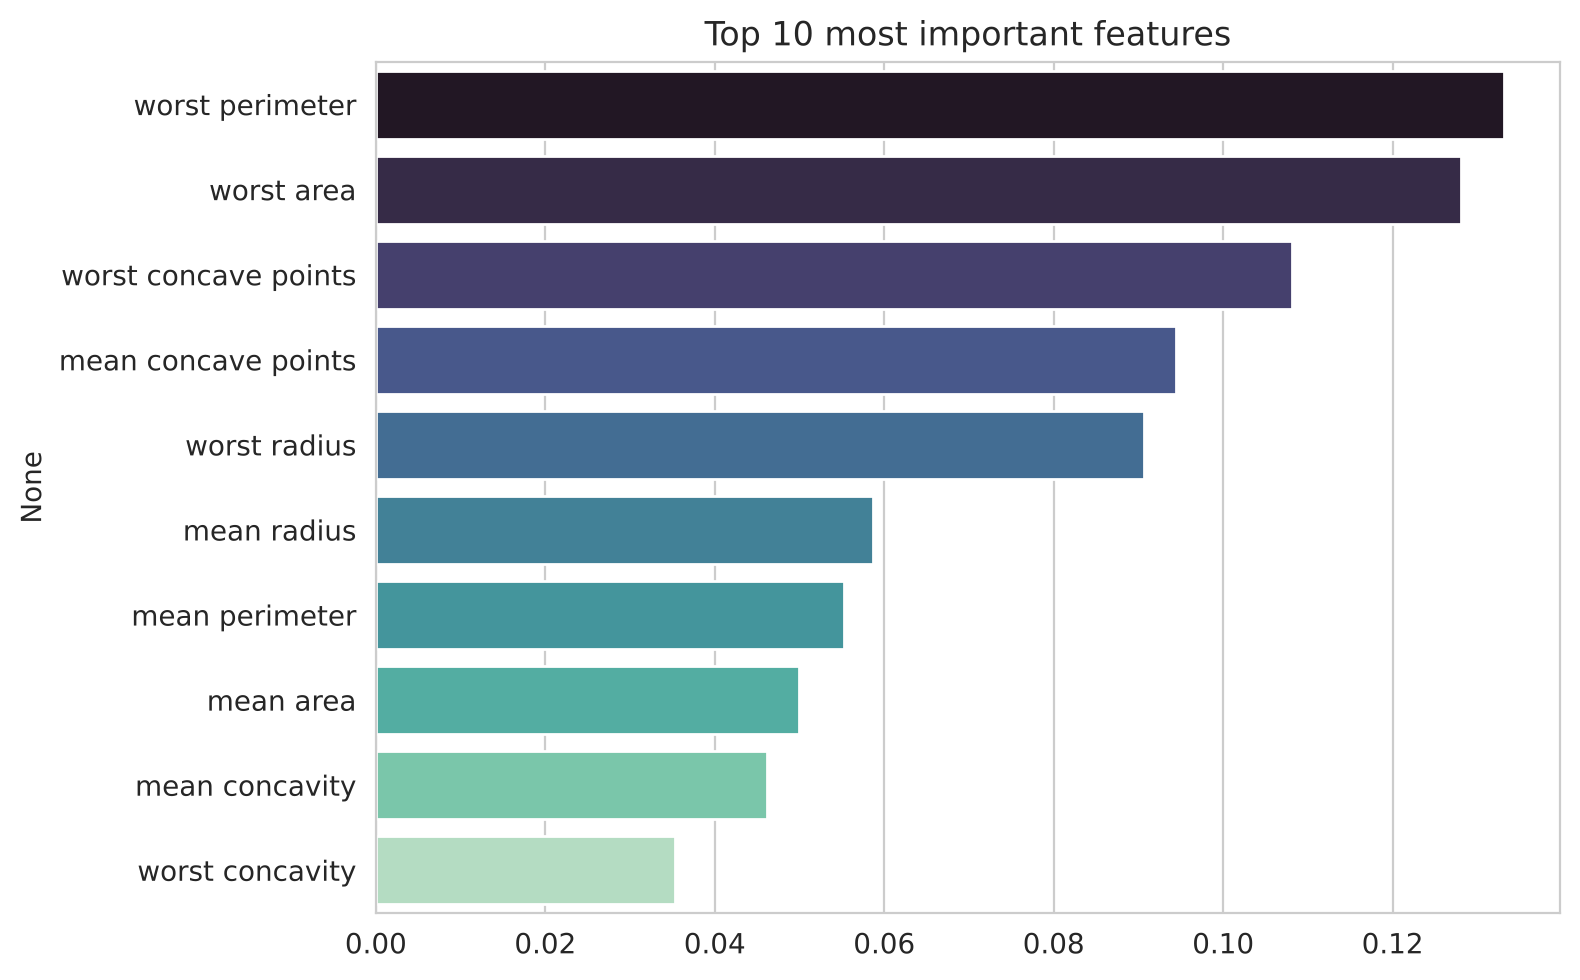

In [11]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette="mako", ax=ax)
ax.set_title("Top 10 most important features")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=120)
plt.show()

## 8. Conclusion
- All four models performed well (91–98% test accuracy) because the features separate the two classes clearly.
- **Logistic Regression was the best model: 98.25% test accuracy**, with 98% recall for malignant tumors (only 1 of 42 cancer cases missed).
- Simple, well-scaled linear models can beat more complex ones on small, clean datasets.
- Size and shape features (**worst perimeter, worst area, worst concave points**) are the strongest predictors.

**Future improvements:**
- Hyperparameter tuning with `GridSearchCV`
- Try SVM and XGBoost
- Deploy the model as a simple web app with Streamlit